# CelebAMask-HQ · Train U-Net phân vùng khuôn mặt (bản v3)

Notebook này làm 4 việc: **(1)** ghép ảnh với nhãn, **(2)** crop quanh mặt bằng RetinaFace, **(3)** train mô hình phân vùng mặt, **(4)** đánh giá và lưu `models/unet_best.pt` cho pipeline.

**Mỗi cell code đều có tiêu đề `CELL n`** ở dòng đầu. Khi cần nói chuyện về một cell, chỉ cần nói "CELL 7".

| CELL | Nhiệm vụ | Chạy khi nào |
|---|---|---|
| 1 | Cấu hình và import | Luôn chạy đầu tiên |
| 2 | Ghép ảnh với nhãn, chia train/val/test | Sau CELL 1 |
| 3 | Nạp RetinaFace để crop quanh mặt | Sau CELL 2 |
| 4 | Hàm đọc cặp ảnh-mask, làm sạch nhãn, vẽ overlay | Sau CELL 3 |
| 5 | **Xem thử dữ liệu** (kiểm tra mask khớp ảnh) | Trước khi train |
| 6 | Dataset và DataLoader | Sau CELL 4 |
| 7 | Hai model: `unet_small` (bản cũ) và `resnet_unet` (bản mới) | Sau CELL 6 |
| 8 | Hàm loss và hàm đánh giá | Sau CELL 7 |
| 9 | Hàm làm sạch mask dự đoán (lấp lỗ, bỏ mảng thừa) | Sau CELL 8 |
| 10 | **Train** và lưu checkpoint tốt nhất | Chạy lâu |
| 11 | Đánh giá trên tập test, xem mask dự đoán | Sau khi train xong |
| 12 | Quét ngưỡng mask trên tập validation | Tùy chọn |
| 13 | Lưu model vào `models/unet_best.pt` cho pipeline | Sau CELL 11 |

Mở notebook ở **thư mục gốc project** trong VS Code, chọn kernel **.venv**. Thiếu thư viện thì chạy trong PowerShell (đã bật môi trường): `python -m pip install ipykernel matplotlib pillow numpy opencv-python facexlib`.

In [1]:
# ===================== CELL 1 · CẤU HÌNH VÀ IMPORT =====================
# Nhiệm vụ: import thư viện và đặt mọi tham số của lần chạy ở MỘT chỗ.
# Khi nào sửa: đổi đường dẫn dữ liệu, số ảnh, số epoch, loại model.
from pathlib import Path
from collections import defaultdict
import random
import time
import shutil
import json

import cv2                      # xử lý ảnh/mask (làm sạch, tìm contour)
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

# --- Đường dẫn ---
# Thư mục chứa CelebA-HQ-img và CelebAMask-HQ-mask-anno
DATA_ROOT = Path(r"C:\Users\NAO\face_detection_segmentation\data\raw\CelebAMask-HQ")
RUN_DIR = Path("models/unet_runs")      # mỗi lần train tạo một thư mục con ở đây

# --- Quy mô lần chạy ---
MAX_IMAGES = 6000   # số ảnh dùng (lần chạy thử trước dùng 1500). Đã đo: 1200 ảnh train ~ 110 giây/epoch
EPOCHS = 8          # số lượt train (lần chạy thử trước dùng 5)
BATCH_SIZE = 8      # báo CUDA out of memory thì giảm xuống 4 hoặc 2

# --- Chọn model ---
# "resnet_unet": U-Net có encoder ResNet34 pretrained (khuyên dùng)
# "unet_small" : U-Net nhỏ bản cũ (dùng làm baseline để so sánh trong báo cáo)
MODEL_NAME = "resnet_unet"
# True: báo lỗi và DỪNG nếu không tải được trọng số ImageNet cho ResNet34.
# (Lần chạy trước tải lỗi mạng nên model bị train từ đầu mà không ai biết.)
# Nếu mạng chập chờn: chạy lại cell, hoặc đặt False để chủ động train từ đầu.
REQUIRE_PRETRAINED = True
LR = {"resnet_unet": 3e-4, "unet_small": 1e-3}[MODEL_NAME]   # tốc độ học theo từng model

# --- Dữ liệu ---
SIZE = 256          # kích thước ảnh đưa vào model (256x256)
MARGIN = 0.25       # mở rộng khung crop 25% mỗi bên (giống lúc chạy thật)
SEED = 42           # cố định ngẫu nhiên để chạy lại ra cùng kết quả

# --- Làm sạch nhãn chuẩn ---
# True: trừ vùng tóc khỏi mask và bỏ các "tua" mảnh lấn lên tóc
CLEAN_LABELS = True
LABEL_OPEN_KERNEL = 31   # kích thước dùng bỏ tua (ảnh gốc 1024px). Tua còn -> tăng; mất chi tiết môi/mắt -> giảm

random.seed(SEED)
torch.manual_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError("Chọn kernel .venv đã chạy được PyTorch CUDA.")
device = torch.device("cuda")
print(torch.__version__, torch.cuda.get_device_name(0))

2.11.0+cu128 NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Ghép ảnh với nhãn theo ID
Mask mặt = da + mũi + mắt + lông mày + miệng + môi (**không gồm tai, tóc, mũ, cổ, kính**). Chia train/val/test ngẫu nhiên theo ID ảnh với seed cố định.

In [2]:
# ===================== CELL 2 · GHÉP ẢNH VỚI NHÃN, CHIA TẬP =====================
# Nhiệm vụ: tìm file nhãn từng bộ phận của mỗi ảnh, rồi chia train/val/test.
# Kết quả: biến train_samples, val_samples, test_samples (danh sách (id, đường dẫn ảnh)).
image_dir = DATA_ROOT / "CelebA-HQ-img"
mask_dir = DATA_ROOT / "CelebAMask-HQ-mask-anno"
if not image_dir.is_dir() or not mask_dir.is_dir():
    raise FileNotFoundError(f"Kiểm tra DATA_ROOT: {DATA_ROOT}")

# Các bộ phận được gộp thành "mặt" (không tai)
parts = {"skin", "nose", "l_eye", "r_eye", "l_brow", "r_brow", "mouth", "u_lip", "l_lip"}

# annotations[id][bộ phận] = đường dẫn file mask của bộ phận đó
annotations = defaultdict(dict)
for path in mask_dir.rglob("*.png"):
    image_id, _, part = path.stem.partition("_")      # vd "00012_l_eye" -> id=00012, part=l_eye
    if image_id.isdecimal() and part in parts:
        annotations[int(image_id)][part] = path

# hair_ann[id] = file mask TÓC. Dùng để trừ vùng tóc ra khỏi mask mặt (xem CELL 4)
hair_ann = {}
for path in mask_dir.rglob("*_hair.png"):
    image_id = path.stem.partition("_")[0]
    if image_id.isdecimal():
        hair_ann[int(image_id)] = path

# Lấy các ảnh có nhãn da, xáo trộn, rồi cắt MAX_IMAGES ảnh
samples = sorted(
    (int(path.stem), path)
    for path in image_dir.iterdir()
    if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
    and path.stem.isdecimal()
    and "skin" in annotations.get(int(path.stem), {})
)
print(f"Số ảnh có mask da: {len(samples)} | số ảnh có nhãn tóc: {len(hair_ann)}")
random.Random(SEED).shuffle(samples)
samples = samples[:MAX_IMAGES]
if len(samples) < 10:
    raise ValueError("Cần ít nhất 10 ảnh có annotation khớp ID.")

# Chia 80% train, 10% val, 10% test
holdout = max(1, len(samples) // 10)
train_samples = samples[:-2 * holdout]
val_samples = samples[-2 * holdout:-holdout]
test_samples = samples[-holdout:]
print("Train / val / test:", len(train_samples), len(val_samples), len(test_samples))

Số ảnh có mask da: 30000 | số ảnh có nhãn tóc: 29300
Train / val / test: 4800 600 600


## 2. Crop quanh mặt
Ảnh và mask được cắt cùng một khung vuông quanh bbox của RetinaFace (mở rộng `MARGIN`), rồi resize về 256×256. Cách này giống lúc chạy thật nên model không bị lệch giữa train và demo.

In [3]:
# ===================== CELL 3 · NẠP RETINAFACE ĐỂ CROP =====================
# Nhiệm vụ: dùng RetinaFace (facexlib) tìm khung mặt, rồi crop quanh khung đó.
# Lần chạy đầu sẽ tự tải trọng số RetinaFace nên cần có mạng.
# Nếu RetinaFace không tìm thấy mặt khớp với nhãn (IoU < 0.3) thì dùng khung lấy từ mask.
from facexlib.detection import init_detection_model

crop_detector = init_detection_model("retinaface_mobile0.25", half=False)
bbox_cache = {}        # lưu khung đã tìm để các epoch sau không phải chạy lại RetinaFace
fallback_ids = set()   # các ảnh phải dùng khung từ mask (để thống kê)


@torch.inference_mode()
def get_crop_bbox(image_id, image, label_box):
    """Trả về khung mặt (x1, y1, x2, y2) dùng để crop. image: ảnh PIL RGB. label_box: khung lấy từ mask."""
    if image_id in bbox_cache:
        return bbox_cache[image_id]

    bgr = cv2.cvtColor(np.asarray(image), cv2.COLOR_RGB2BGR)   # facexlib cần BGR
    detections = crop_detector.detect_faces(bgr, 0.8)           # 0.8 = ngưỡng tin cậy

    gx1, gy1, gx2, gy2 = label_box
    label_area = (gx2 - gx1) * (gy2 - gy1)
    best_box, best_iou = label_box, 0.0

    # Chọn khung RetinaFace trùng nhiều nhất với khung lấy từ nhãn (tránh chọn nhầm mặt khác)
    for detection in detections:
        x1, y1, x2, y2 = map(float, detection[:4])
        if x2 <= x1 or y2 <= y1:
            continue
        overlap_w = max(0, min(x2, gx2) - max(x1, gx1))
        overlap_h = max(0, min(y2, gy2) - max(y1, gy1))
        intersection = overlap_w * overlap_h
        union = label_area + (x2 - x1) * (y2 - y1) - intersection
        iou = intersection / union
        if iou > best_iou:
            best_box, best_iou = (x1, y1, x2, y2), iou

    if best_iou < 0.3:                 # không khớp -> dùng khung từ nhãn
        best_box = label_box
        fallback_ids.add(image_id)

    bbox_cache[image_id] = best_box
    return best_box

In [4]:
# ===================== CELL 4 · ĐỌC CẶP ẢNH-MASK, LÀM SẠCH NHÃN, VẼ OVERLAY =====================
# Nhiệm vụ: định nghĩa các hàm đọc dữ liệu. CELL này chỉ định nghĩa hàm, không in ra gì.
#   remove_thin_parts : bỏ tua mảnh, giữ mảnh lớn nhất của mask
#   load_pair         : trả về (ảnh gốc, ảnh crop 256, mask crop 256)
#   overlay           : tô xanh mask lên ảnh
#   show_examples     : vẽ lưới ảnh gốc / crop / mask / overlay (và dự đoán nếu có)

def remove_thin_parts(mask_bool):
    """Bỏ các tua mảnh (vd tua lấn lên tóc) rồi giữ mảnh liên thông lớn nhất."""
    m = mask_bool.astype(np.uint8)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (LABEL_OPEN_KERNEL, LABEL_OPEN_KERNEL))
    opened = cv2.morphologyEx(m, cv2.MORPH_OPEN, kernel)       # mở: xóa phần nhô mảnh hơn kernel
    if not opened.any():                                         # nếu xóa hết thì giữ bản gốc
        opened = m
    n, labels, stats, _ = cv2.connectedComponentsWithStats(opened)
    if n > 1:                                                    # giữ mảnh có diện tích lớn nhất
        opened = (labels == 1 + stats[1:, cv2.CC_STAT_AREA].argmax()).astype(np.uint8)
    return opened.astype(bool)


def load_pair(sample):
    """sample = (id, đường dẫn ảnh). Trả về (ảnh gốc PIL, ảnh crop numpy HxWx3, mask crop numpy bool)."""
    image_id, path = sample
    with Image.open(path) as source:
        original = source.convert("RGB")

    # Gộp các bộ phận mặt thành một mask nhị phân, phóng về kích thước ảnh gốc
    merged = np.zeros((original.height, original.width), dtype=bool)
    for annotation in annotations[image_id].values():
        with Image.open(annotation) as source:
            part = source.convert("L").resize(original.size, Image.Resampling.NEAREST)
        merged |= np.asarray(part) > 0

    if CLEAN_LABELS:
        # Bước 1: trừ vùng tóc (nếu có nhãn tóc) khỏi mask mặt
        if image_id in hair_ann:
            with Image.open(hair_ann[image_id]) as source:
                hair = source.convert("L").resize(original.size, Image.Resampling.NEAREST)
            without_hair = merged & ~(np.asarray(hair) > 0)
            if without_hair.any():
                merged = without_hair
        # Bước 2: bỏ tua mảnh, giữ mảnh lớn nhất
        merged = remove_thin_parts(merged)

    mask = Image.fromarray(merged.astype(np.uint8) * 255)
    box = mask.getbbox()
    if box is None:
        raise ValueError(f"Mask rỗng cho ảnh {image_id}")

    # Lấy khung mặt từ RetinaFace, mở rộng thành hình vuông có margin
    left, top, right, bottom = get_crop_bbox(image_id, original, box)
    side = int(np.ceil(max(right - left, bottom - top) * (1 + 2 * MARGIN)))
    x = (left + right - side) // 2
    y = (top + bottom - side) // 2
    crop = (x, y, x + side, y + side)           # khung vuông; phần vượt ảnh sẽ được pad đen

    # Cắt ảnh và mask CÙNG khung, resize về 256x256 (mask dùng NEAREST để giữ nhị phân)
    image = np.asarray(original.crop(crop).resize((SIZE, SIZE), Image.Resampling.BILINEAR))
    target = np.asarray(mask.crop(crop).resize((SIZE, SIZE), Image.Resampling.NEAREST)) > 0
    return original, image, target


def overlay(image, mask):
    """Tô xanh vùng mask lên ảnh."""
    result = image.copy()
    result[mask] = 0.55 * image[mask] + 0.45 * np.array([0, 255, 90])
    return result


def show_examples(samples, predictions=None):
    """Vẽ lưới ví dụ. predictions: dict {tiêu đề: mảng mask dự đoán (N,256,256)} hoặc None."""
    titles = ["Ảnh gốc", "Crop", "Mask chuẩn", "Overlay chuẩn"]
    if predictions:
        titles += [f"Overlay {name}" for name in predictions]
    fig, axes = plt.subplots(len(samples), len(titles), squeeze=False,
                             figsize=(3 * len(titles), 2.6 * len(samples)))
    for index, sample in enumerate(samples):
        original, image, mask = load_pair(sample)
        panels = [original, image, mask, overlay(image, mask)]
        if predictions:
            panels += [overlay(image, pred[index]) for pred in predictions.values()]
        for axis, panel, title in zip(axes[index], panels, titles):
            axis.imshow(panel, cmap="gray", vmin=0, vmax=1)
            axis.set_title(f"{title} · {sample[0]}", fontsize=9)
            axis.axis("off")
    fig.tight_layout()
    plt.show()

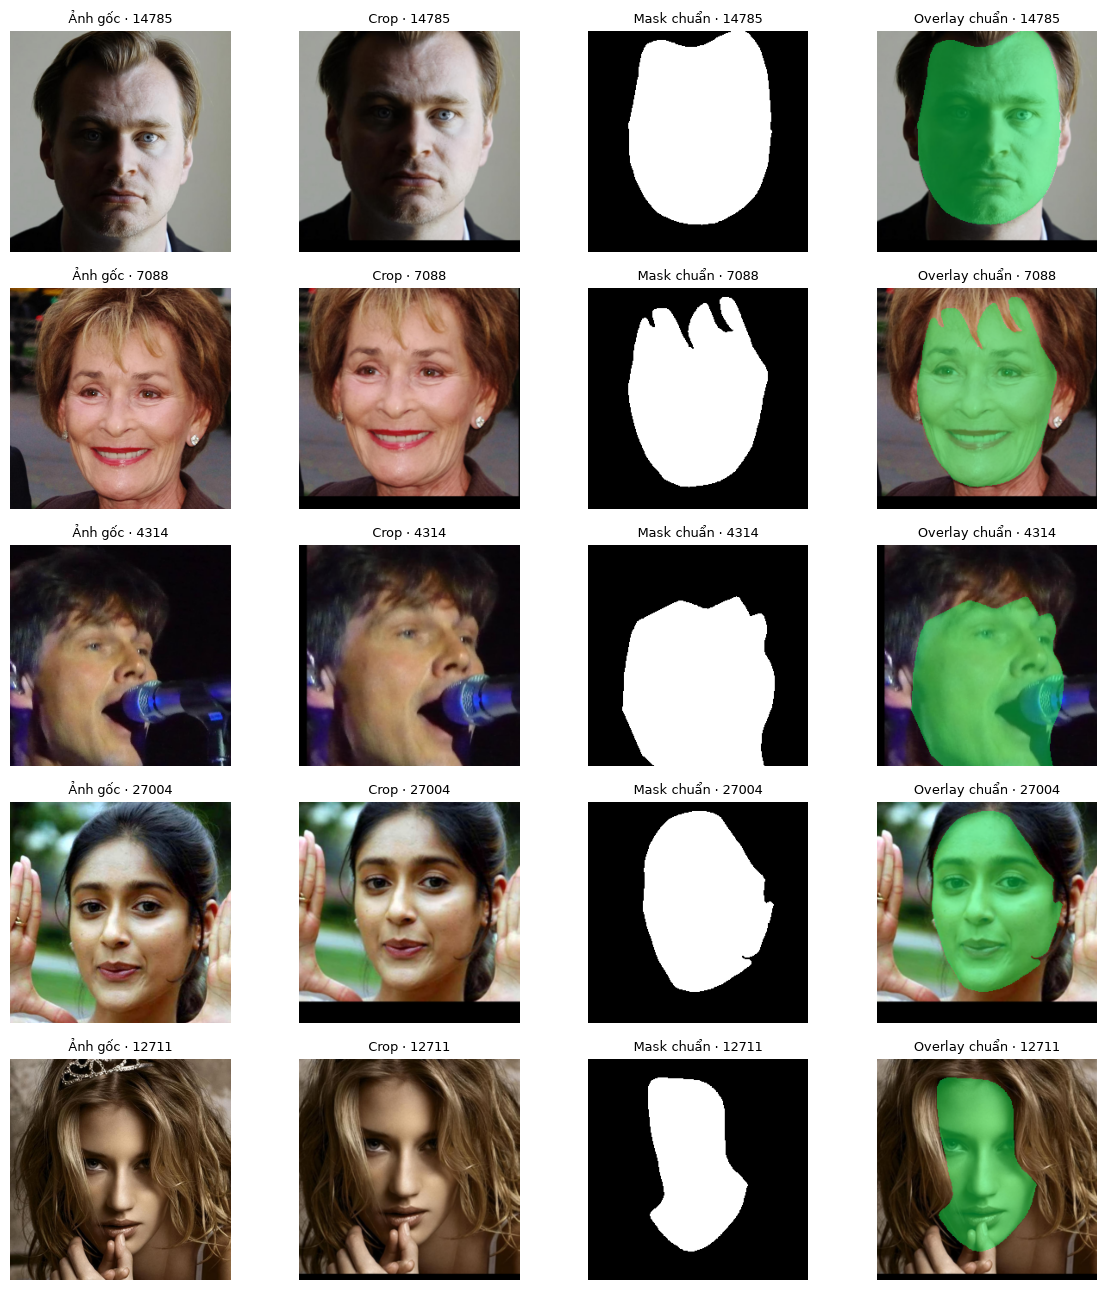

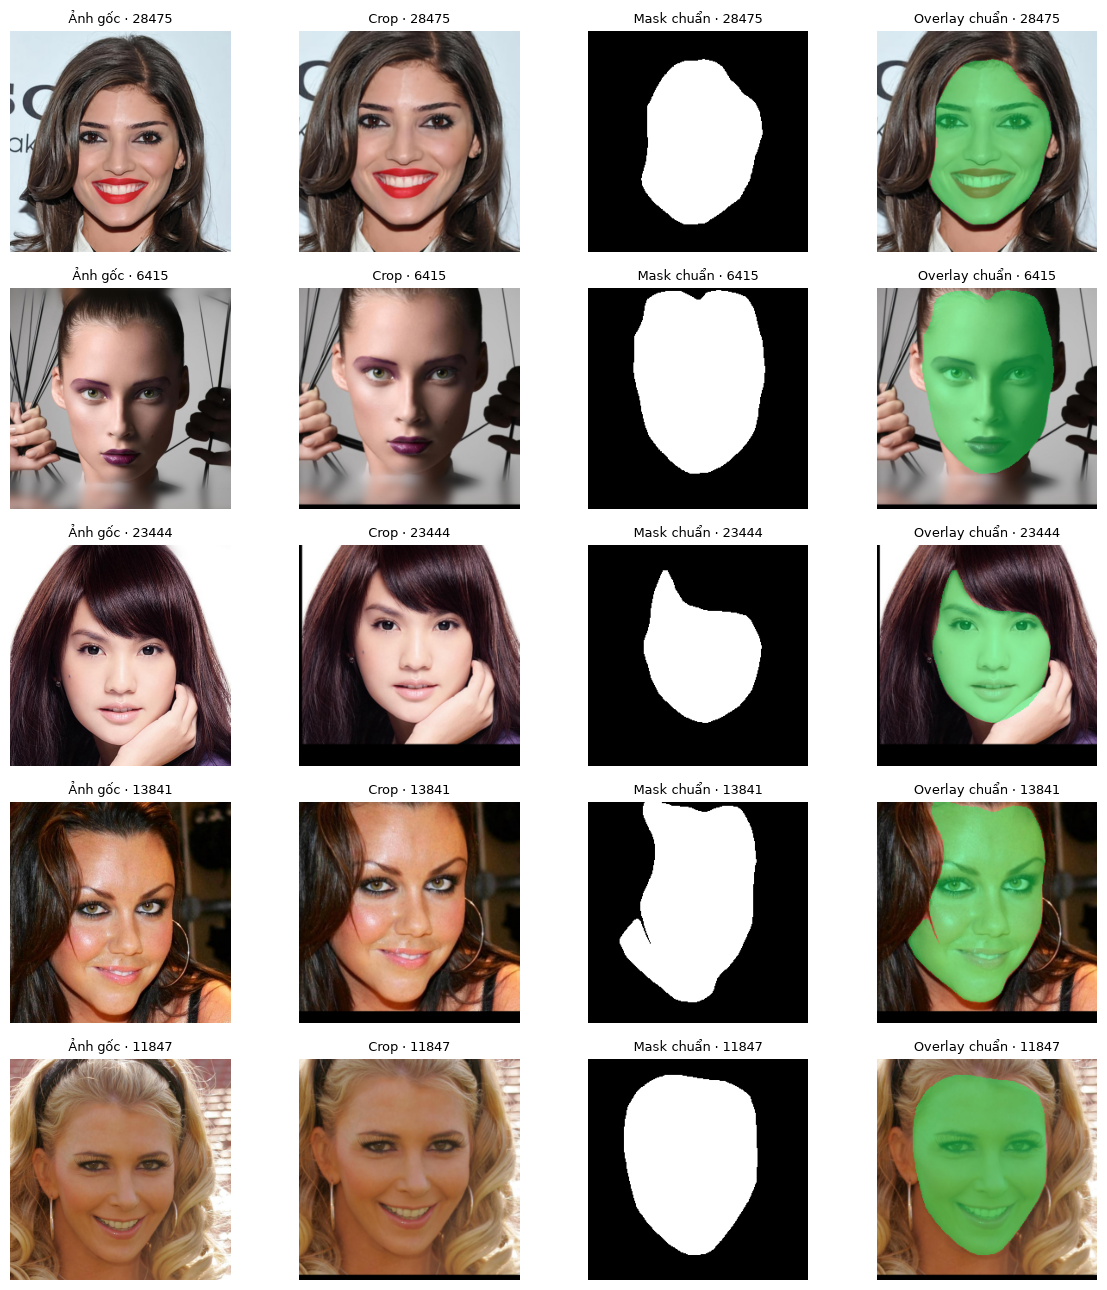

Số ảnh phải dùng khung từ mask thay vì RetinaFace (cho đến lúc này): 0


In [5]:
# ===================== CELL 5 · XEM THỬ DỮ LIỆU (KIỂM TRA TRƯỚC KHI TRAIN) =====================
# Nhiệm vụ: vẽ 10 ảnh train đầu tiên để kiểm tra bằng mắt.
# Cần thấy: mask tô đúng da mặt, mắt/mũi/miệng nằm trong mask, KHÔNG lấn lên tóc.
# Nếu còn tua xanh trên tóc: tăng LABEL_OPEN_KERNEL ở CELL 1 rồi chạy lại từ CELL 1.
# Nếu mất chi tiết môi/mắt: giảm LABEL_OPEN_KERNEL.
for start in range(0, min(10, len(train_samples)), 5):
    show_examples(train_samples[start:min(start + 5, 10)])
print(f"Số ảnh phải dùng khung từ mask thay vì RetinaFace (cho đến lúc này): {len(fallback_ids)}")

## 3. Dataset, model, loss

In [6]:
# ===================== CELL 6 · DATASET VÀ DATALOADER =====================
# Nhiệm vụ: đóng gói dữ liệu cho PyTorch.
# Augmentation (chỉ khi train): 35% ảnh bị thu nhỏ rồi phóng lại để mô phỏng MẶT NHỎ/MỜ trong đám đông.
# num_workers=0 vì chạy trong notebook trên Windows.
class FaceDataset(Dataset):
    def __init__(self, samples, augment=False):
        self.samples = samples
        self.augment = augment

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        _, image, mask = load_pair(self.samples[index])
        if self.augment and random.random() < 0.35:
            side = random.randint(48, 128)      # thu nhỏ về cạnh ngẫu nhiên 48-128 px
            image = Image.fromarray(image).resize((side, side), Image.Resampling.BILINEAR)
            image = np.asarray(image.resize((SIZE, SIZE), Image.Resampling.BILINEAR))
        # Ảnh về [0,1], đổi trục thành (3,H,W); mask thành (1,H,W)
        image = torch.from_numpy(image.astype(np.float32) / 255).permute(2, 0, 1)
        target = torch.from_numpy(mask.astype(np.float32))[None]
        return image, target


def make_loader(samples, training=False):
    """training=True: xáo trộn và bật augmentation."""
    return DataLoader(FaceDataset(samples, augment=training), batch_size=BATCH_SIZE,
                      shuffle=training, num_workers=0, pin_memory=True)

In [7]:
# ===================== CELL 7 · ĐỊNH NGHĨA MODEL =====================
# Nhiệm vụ: định nghĩa 2 model và hàm build_model() chọn theo MODEL_NAME (CELL 1).
#   UNetSmall : U-Net nhỏ bản cũ, chỉ 2 lần pool nên "nhìn" được vùng rất nhỏ (~32px)
#               -> mask bị thủng ở vùng tối và tô thừa lên vật có màu da. Giữ làm baseline.
#   ResNetUNet: U-Net với encoder ResNet34 pretrained, nhìn được cả khuôn mặt (khuyên dùng).
from torchvision.models import resnet34, ResNet34_Weights


def conv_block(in_channels, out_channels):
    """Khối 2 lớp Conv3x3 + BatchNorm + ReLU, dùng ở cả hai model."""
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1),
        nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, 3, padding=1),
        nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
    )


class UNetSmall(nn.Module):
    """Baseline: U-Net nhỏ train từ đầu (bản cũ)."""
    def __init__(self):
        super().__init__()
        self.enc1 = conv_block(3, 16)
        self.enc2 = conv_block(16, 32)
        self.center = conv_block(32, 64)
        self.pool = nn.MaxPool2d(2)
        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = conv_block(64, 32)
        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = conv_block(32, 16)
        self.head = nn.Conv2d(16, 1, 1)

    def forward(self, image):
        first = self.enc1(image)
        second = self.enc2(self.pool(first))
        center = self.center(self.pool(second))
        second_up = self.dec2(torch.cat((self.up2(center), second), dim=1))
        first_up = self.dec1(torch.cat((self.up1(second_up), first), dim=1))
        return self.head(first_up)


class UpBlock(nn.Module):
    """Một bước giải mã: phóng to ảnh đặc trưng, nối với đặc trưng cùng cỡ từ encoder, rồi conv."""
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.block = conv_block(in_ch + skip_ch, out_ch)

    def forward(self, x, skip):
        x = nn.functional.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return self.block(torch.cat((x, skip), dim=1))


class ResNetUNet(nn.Module):
    """U-Net với encoder ResNet34 pretrained trên ImageNet."""
    def __init__(self, pretrained=True):
        super().__init__()
        self.pretrained = False          # ghi nhận model có thực sự dùng trọng số ImageNet không
        if pretrained:
            try:
                backbone = resnet34(weights=ResNet34_Weights.IMAGENET1K_V1)
                self.pretrained = True
            except Exception as error:   # không tải được trọng số (lỗi mạng)
                if REQUIRE_PRETRAINED:
                    raise RuntimeError(f"Không tải được trọng số ImageNet: {error}. "
                                       "Chạy lại cell này, hoặc đặt REQUIRE_PRETRAINED = False ở CELL 1.")
                print("Không tải được trọng số pretrained, train từ đầu:", error)
                backbone = resnet34(weights=None)
        else:
            backbone = resnet34(weights=None)
        self.stem = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu)   # /2,  64 kênh
        self.pool = backbone.maxpool                                              # /4
        self.l1, self.l2, self.l3, self.l4 = (backbone.layer1, backbone.layer2,   # /4, /8, /16, /32
                                              backbone.layer3, backbone.layer4)
        self.up4 = UpBlock(512, 256, 256)
        self.up3 = UpBlock(256, 128, 128)
        self.up2 = UpBlock(128, 64, 64)
        self.up1 = UpBlock(64, 64, 32)
        self.head = nn.Conv2d(32, 1, 1)
        # Chuẩn hóa ImageNet đặt trong model để Dataset chỉ cần chia 255
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        size = x.shape[-2:]
        x = (x - self.mean) / self.std
        s0 = self.stem(x)                 # /2
        s1 = self.l1(self.pool(s0))       # /4
        s2 = self.l2(s1)                  # /8
        s3 = self.l3(s2)                  # /16
        s4 = self.l4(s3)                  # /32  (tầng sâu nhất, nhìn được cả khuôn mặt)
        d = self.up4(s4, s3)
        d = self.up3(d, s2)
        d = self.up2(d, s1)
        d = self.up1(d, s0)
        d = nn.functional.interpolate(d, size=size, mode="bilinear", align_corners=False)
        return self.head(d)               # trả về logits (chưa sigmoid), kích thước bằng ảnh vào


def build_model():
    """Tạo model theo MODEL_NAME đã đặt ở CELL 1."""
    return {"resnet_unet": ResNetUNet, "unet_small": UNetSmall}[MODEL_NAME]()


# Kiểm tra nhanh: đưa 1 batch giả vào, kích thước ra phải là (2, 1, 256, 256)
with torch.inference_mode():
    _probe = build_model().eval()(torch.zeros(2, 3, SIZE, SIZE))
print(MODEL_NAME, "-> kích thước đầu ra:", tuple(_probe.shape))
print("Dùng trọng số ImageNet:", getattr(build_model(), "pretrained", False))
del _probe

resnet_unet -> kích thước đầu ra: (2, 1, 256, 256)
Dùng trọng số ImageNet: True


In [8]:
# ===================== CELL 8 · LOSS VÀ HÀM ĐÁNH GIÁ =====================
# Nhiệm vụ:
#   segmentation_loss : BCE + Dice (BCE học từng pixel, Dice học độ khớp cả vùng)
#   evaluate          : tính Dice và IoU trung bình theo ảnh (mask thô, ngưỡng 0.5)
bce = nn.BCEWithLogitsLoss()


def segmentation_loss(logits, target):
    prob = logits.float().sigmoid().flatten(1)
    target_flat = target.flatten(1)
    intersection = (prob * target_flat).sum(dim=1)
    dice = (2 * intersection + 1e-6) / (prob.sum(dim=1) + target_flat.sum(dim=1) + 1e-6)
    return bce(logits, target) + 1 - dice.mean()


@torch.inference_mode()
def evaluate(model, loader):
    """Trả về [Dice, IoU] trung bình trên loader. logits >= 0 tương đương xác suất >= 0.5."""
    model.eval()
    scores = []
    for images, masks in loader:
        pred = model(images.to(device)).flatten(1) >= 0
        truth = masks.to(device).flatten(1).bool()
        intersection = (pred & truth).sum(dim=1)
        union = (pred | truth).sum(dim=1)
        dice = 2 * intersection / (pred.sum(dim=1) + truth.sum(dim=1)).clamp_min(1)
        iou = intersection / union.clamp_min(1)
        scores.append(torch.stack((dice, iou), dim=1).cpu())
    return torch.cat(scores).mean(dim=0).tolist()

In [9]:
# ===================== CELL 9 · LÀM SẠCH MASK DỰ ĐOÁN =====================
# Nhiệm vụ: hậu xử lý mask do model dự đoán:
#   - giữ MẢNH LỚN NHẤT  -> xóa các mảng xanh lẻ ngoài nền/tóc
#   - LẤP LỖ bên trong   -> vá chỗ bị thủng ở má, vùng tối (quan trọng khi dùng để che mặt)
# Hàm này sẽ được dùng lại trong pipeline thật (mask_mapping).
def clean_mask(mask):
    """mask: mảng bool (H, W). Trả về mảng bool đã giữ mảnh lớn nhất và lấp lỗ."""
    m = mask.astype(np.uint8)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:                                   # mask rỗng -> giữ nguyên
        return mask
    m = (labels == 1 + stats[1:, cv2.CC_STAT_AREA].argmax()).astype(np.uint8)
    contours, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(m)
    cv2.drawContours(filled, contours, -1, 1, thickness=cv2.FILLED)   # tô đặc đường viền ngoài = lấp lỗ
    return filled.astype(bool)


@torch.inference_mode()
def evaluate_cleaned(model, loader, threshold=0.5):
    """Giống evaluate nhưng áp dụng clean_mask lên từng dự đoán. Trả về [Dice, IoU]."""
    model.eval()
    scores = []
    for images, masks in loader:
        probs = model(images.to(device)).sigmoid()[:, 0].cpu().numpy()
        truths = masks[:, 0].numpy() > 0.5
        for prob, truth in zip(probs, truths):
            pred = clean_mask(prob >= threshold)
            intersection = (pred & truth).sum()
            union = (pred | truth).sum()
            dice = 2 * intersection / max(pred.sum() + truth.sum(), 1)
            scores.append((dice, intersection / max(union, 1)))
    return np.mean(scores, axis=0).tolist()

## 4. Train và lưu checkpoint
Mỗi lần train tạo một thư mục riêng dưới `models/unet_runs/` và lưu `unet_best.pt` theo Dice validation cao nhất. **Epoch đầu chậm hơn** vì RetinaFace phải tìm khung cho từng ảnh (kết quả được nhớ lại cho các epoch sau).

In [10]:
# ===================== CELL 10 · TRAIN =====================
# Nhiệm vụ: train model, mỗi epoch đánh giá trên tập val và lưu checkpoint khi Dice val tăng.
# Kết quả: biến `checkpoint` (đường dẫn file trọng số tốt nhất), dùng ở CELL 11-13.
# Chạy lâu. Có thể bấm Interrupt để dừng; checkpoint tốt nhất đã lưu vẫn còn.
from datetime import datetime

random.seed(SEED)
torch.manual_seed(SEED)
train_loader = make_loader(train_samples, training=True)
val_loader = make_loader(val_samples)

model = build_model().to(device)                                  # model theo MODEL_NAME
trained_pretrained = getattr(model, "pretrained", False)          # lần train này có dùng trọng số ImageNet không
print("Dùng trọng số ImageNet:", trained_pretrained)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)         # LR theo model (CELL 1)
scaler = torch.amp.GradScaler("cuda")                             # mixed precision: nhanh hơn, tiết kiệm VRAM

run_path = RUN_DIR / datetime.now().strftime("%Y%m%d_%H%M%S_%f")  # thư mục riêng cho lần chạy này
run_path.mkdir(parents=True)
checkpoint = run_path / "unet_best.pt"
best_dice = -1.0

for epoch in range(1, EPOCHS + 1):
    start = time.perf_counter()
    model.train()
    total_loss = 0.0
    for step, (images, masks) in enumerate(train_loader, start=1):
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda"):                  # tính ở độ chính xác hỗn hợp
            loss = segmentation_loss(model(images), masks)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * len(images)
        if step % 20 == 0 or step == len(train_loader):
            print(f"Epoch {epoch} · batch {step}/{len(train_loader)}")

    dice, iou = evaluate(model, val_loader)                       # đánh giá trên tập val
    print(f"Epoch {epoch} | loss={total_loss / len(train_samples):.4f} | "
          f"val Dice={dice:.4f} | val IoU={iou:.4f} | {time.perf_counter() - start:.1f}s")
    if dice > best_dice:                                          # chỉ lưu khi tốt hơn trước
        best_dice = dice
        torch.save(model.state_dict(), checkpoint)
        print("Đã lưu:", checkpoint.resolve())

Dùng trọng số ImageNet: True
Epoch 1 · batch 20/600
Epoch 1 · batch 40/600
Epoch 1 · batch 60/600
Epoch 1 · batch 80/600
Epoch 1 · batch 100/600
Epoch 1 · batch 120/600
Epoch 1 · batch 140/600
Epoch 1 · batch 160/600
Epoch 1 · batch 180/600
Epoch 1 · batch 200/600
Epoch 1 · batch 220/600
Epoch 1 · batch 240/600
Epoch 1 · batch 260/600
Epoch 1 · batch 280/600
Epoch 1 · batch 300/600
Epoch 1 · batch 320/600
Epoch 1 · batch 340/600
Epoch 1 · batch 360/600
Epoch 1 · batch 380/600
Epoch 1 · batch 400/600
Epoch 1 · batch 420/600
Epoch 1 · batch 440/600
Epoch 1 · batch 460/600
Epoch 1 · batch 480/600
Epoch 1 · batch 500/600
Epoch 1 · batch 520/600
Epoch 1 · batch 540/600
Epoch 1 · batch 560/600
Epoch 1 · batch 580/600
Epoch 1 · batch 600/600
Epoch 1 | loss=0.3237 | val Dice=0.9723 | val IoU=0.9470 | 856.6s
Đã lưu: C:\Users\NAO\face_detection_segmentation\models\unet_runs\20261120_080838_558128\unet_best.pt
Epoch 2 · batch 20/600
Epoch 2 · batch 40/600
Epoch 2 · batch 60/600
Epoch 2 · batch 80

## 5. Đánh giá trên test và xem mask dự đoán
Cột **"dự đoán thô"** là đầu ra trực tiếp của model, cột **"sau làm sạch"** đã giữ mảnh lớn nhất và lấp lỗ. So hai cột để thấy tác dụng của `clean_mask`.

Test (600 ảnh) · resnet_unet
  Thô         : Dice=0.9788 · IoU=0.9590
  Sau làm sạch: Dice=0.9788 · IoU=0.9591


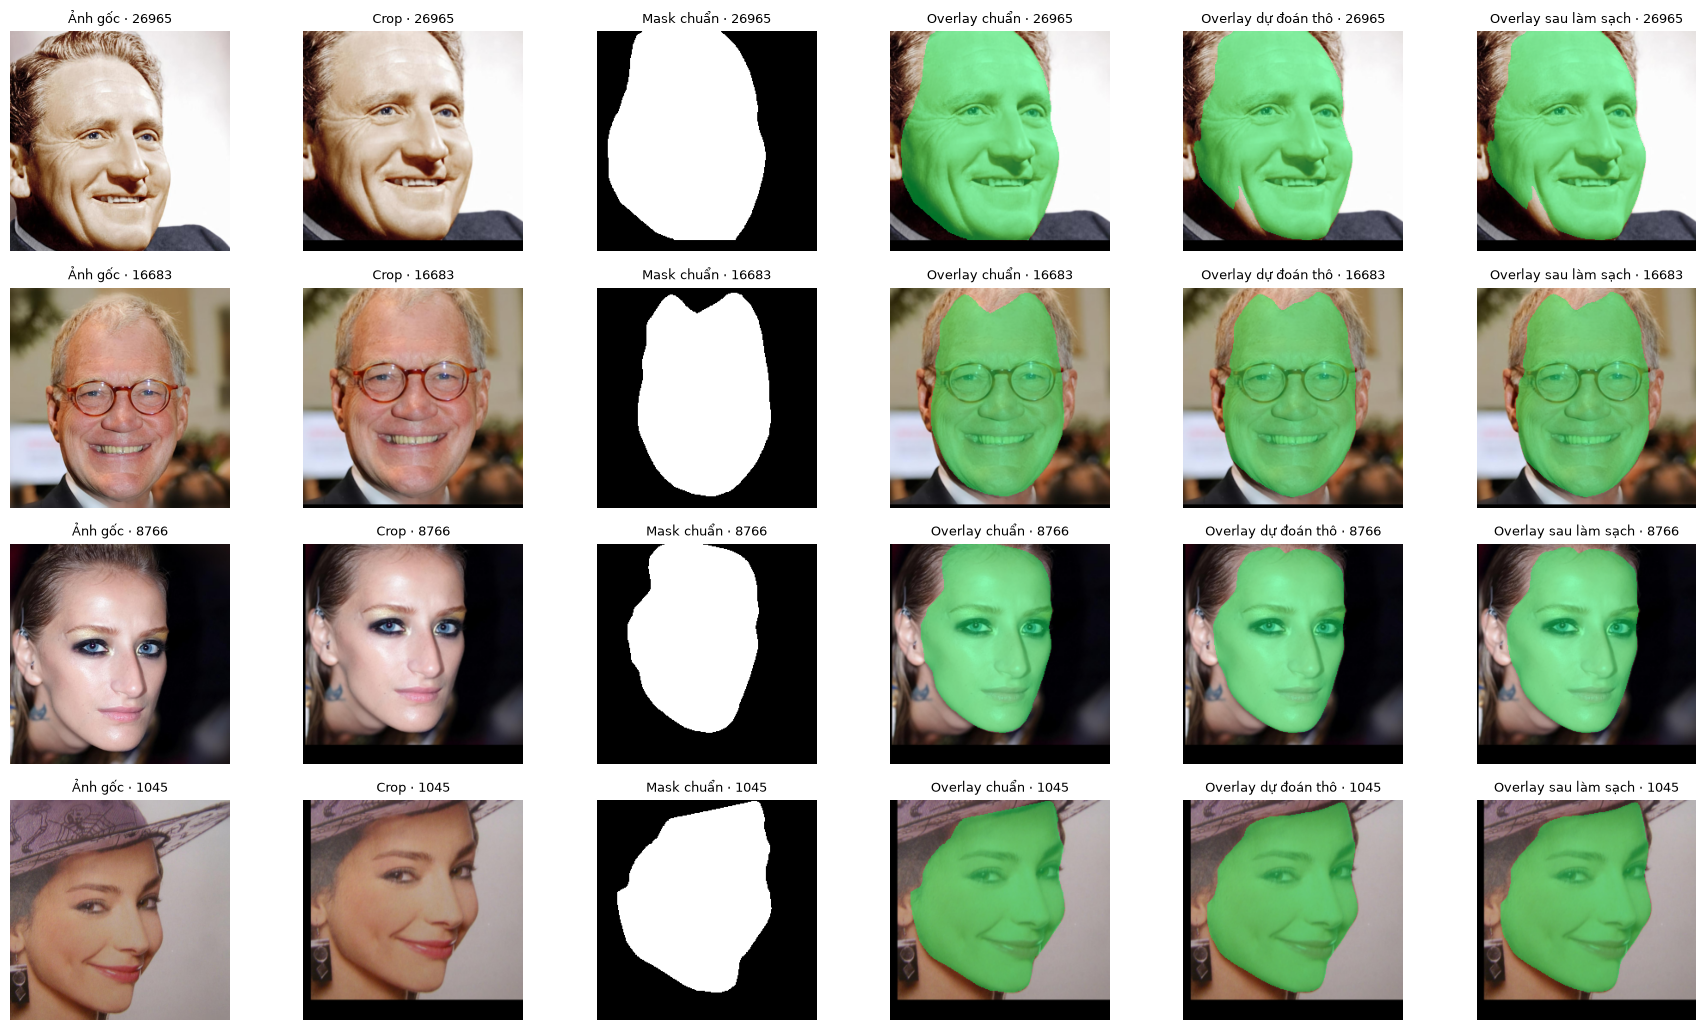

In [11]:
# ===================== CELL 11 · ĐÁNH GIÁ TRÊN TEST VÀ XEM MASK DỰ ĐOÁN =====================
# Nhiệm vụ: nạp checkpoint tốt nhất, đo Dice/IoU trên tập test (thô và sau làm sạch), vẽ 4 ảnh ví dụ.
# Nếu vừa khởi động lại kernel và muốn đánh giá checkpoint cũ, đặt đường dẫn vào dòng dưới
# (vd Path("models/unet_runs/20261120_071415_195904/unet_best.pt")). Để None = dùng lần train vừa rồi.
CHECKPOINT_OVERRIDE = None
ckpt = Path(CHECKPOINT_OVERRIDE) if CHECKPOINT_OVERRIDE else checkpoint

model = build_model().to(device)
model.load_state_dict(torch.load(ckpt, map_location=device, weights_only=True))
model.eval()

test_loader = make_loader(test_samples)
raw_dice, raw_iou = evaluate(model, test_loader)
clean_dice, clean_iou = evaluate_cleaned(model, test_loader)
print(f"Test ({len(test_samples)} ảnh) · {MODEL_NAME}")
print(f"  Thô         : Dice={raw_dice:.4f} · IoU={raw_iou:.4f}")
print(f"  Sau làm sạch: Dice={clean_dice:.4f} · IoU={clean_iou:.4f}")

# Vẽ 4 ảnh test: mask chuẩn, dự đoán thô, dự đoán sau làm sạch
preview_samples = test_samples[:4]
preview_data = FaceDataset(preview_samples)
with torch.inference_mode():
    images = torch.stack([preview_data[i][0] for i in range(len(preview_data))]).to(device)
    raw_pred = (model(images)[:, 0] >= 0).cpu().numpy()
clean_pred = np.stack([clean_mask(p) for p in raw_pred])
show_examples(preview_samples, {"dự đoán thô": raw_pred, "sau làm sạch": clean_pred})

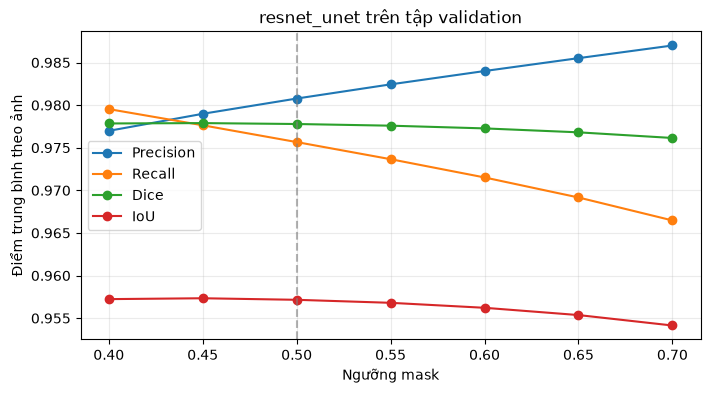

Ngưỡng có Dice cao nhất trên validation: 0.45
0.40 | Precision=0.9770 | Recall=0.9795 | Dice=0.9778 | IoU=0.9572
0.45 | Precision=0.9790 | Recall=0.9776 | Dice=0.9779 | IoU=0.9573
0.50 | Precision=0.9808 | Recall=0.9757 | Dice=0.9778 | IoU=0.9572
0.55 | Precision=0.9824 | Recall=0.9737 | Dice=0.9776 | IoU=0.9568
0.60 | Precision=0.9840 | Recall=0.9715 | Dice=0.9773 | IoU=0.9562
0.65 | Precision=0.9855 | Recall=0.9692 | Dice=0.9768 | IoU=0.9554
0.70 | Precision=0.9870 | Recall=0.9665 | Dice=0.9761 | IoU=0.9541


In [12]:
# ===================== CELL 12 · QUÉT NGƯỠNG MASK (TÙY CHỌN) =====================
# Nhiệm vụ: thử các ngưỡng 0.40-0.70 trên tập val, xem Precision/Recall/Dice/IoU thay đổi thế nào.
# Dùng cho báo cáo. Thường khác biệt rất nhỏ, nên không cần chỉnh nhiều.
model.load_state_dict(torch.load(ckpt, map_location=device, weights_only=True))
model.eval()

thresholds = [0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]
scores = {t: [] for t in thresholds}

with torch.inference_mode():
    for images, masks in make_loader(val_samples):
        probs = model(images.to(device)).sigmoid().flatten(1)
        truth = masks.to(device).flatten(1).bool()
        for t in thresholds:
            pred = probs >= t
            tp = (pred & truth).sum(dim=1)
            fp = (pred & ~truth).sum(dim=1)
            fn = (~pred & truth).sum(dim=1)
            precision = tp / (tp + fp).clamp_min(1)
            recall = tp / (tp + fn).clamp_min(1)
            dice = 2 * tp / (2 * tp + fp + fn).clamp_min(1)
            iou = tp / (tp + fp + fn).clamp_min(1)
            scores[t].append(torch.stack([precision, recall, dice, iou], dim=1).cpu())

summary = torch.stack([torch.cat(scores[t]).mean(dim=0) for t in thresholds])
names = ["Precision", "Recall", "Dice", "IoU"]

fig, ax = plt.subplots(figsize=(8, 4))
for index, name in enumerate(names):
    ax.plot(thresholds, summary[:, index].tolist(), marker="o", label=name)
ax.axvline(0.50, color="gray", linestyle="--", alpha=0.6)
ax.set(xlabel="Ngưỡng mask", ylabel="Điểm trung bình theo ảnh", title=f"{MODEL_NAME} trên tập validation")
ax.set_xticks(thresholds)
ax.grid(alpha=0.25)
ax.legend()
plt.show()

best_index = summary[:, 2].argmax().item()
print(f"Ngưỡng có Dice cao nhất trên validation: {thresholds[best_index]:.2f}")
for t, row in zip(thresholds, summary.tolist()):
    print(f"{t:.2f} | " + " | ".join(f"{name}={v:.4f}" for name, v in zip(names, row)))

In [13]:
# ===================== CELL 13 · LƯU MODEL CHO PIPELINE =====================
# Nhiệm vụ: sao chép checkpoint tốt nhất thành models/unet_best.pt (đường dẫn pipeline sẽ dùng)
# và ghi lại thông tin lần chạy (model, số ảnh, epoch, điểm test) vào models/unet_best_info.json.
# Chỉ chạy khi hài lòng với kết quả ở CELL 11.
final_path = Path("models/unet_best.pt")
final_path.parent.mkdir(parents=True, exist_ok=True)
shutil.copy(ckpt, final_path)

info = {
    "model": MODEL_NAME, "size": SIZE, "margin": MARGIN,
    "max_images": MAX_IMAGES, "epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": LR,
    "pretrained": globals().get("trained_pretrained"), "clean_labels": CLEAN_LABELS, "label_open_kernel": LABEL_OPEN_KERNEL,
    "face_definition": sorted(parts),
    "test_dice_raw": raw_dice, "test_iou_raw": raw_iou,
    "test_dice_clean": clean_dice, "test_iou_clean": clean_iou,
    "source_checkpoint": str(ckpt),
}
Path("models/unet_best_info.json").write_text(json.dumps(info, ensure_ascii=False, indent=2), encoding="utf-8")
print("Đã lưu:", final_path.resolve())
print(json.dumps(info, ensure_ascii=False, indent=2))

Đã lưu: C:\Users\NAO\face_detection_segmentation\models\unet_best.pt
{
  "model": "resnet_unet",
  "size": 256,
  "margin": 0.25,
  "max_images": 6000,
  "epochs": 8,
  "batch_size": 8,
  "lr": 0.0003,
  "pretrained": true,
  "clean_labels": true,
  "label_open_kernel": 31,
  "face_definition": [
    "l_brow",
    "l_eye",
    "l_lip",
    "mouth",
    "nose",
    "r_brow",
    "r_eye",
    "skin",
    "u_lip"
  ],
  "test_dice_raw": 0.9787735939025879,
  "test_iou_raw": 0.9590396285057068,
  "test_dice_clean": 0.9787940531578488,
  "test_iou_clean": 0.9590775791330297,
  "source_checkpoint": "models\\unet_runs\\20261120_080838_558128\\unet_best.pt"
}
